# Section 1: Setup & Data Loading

In [ ]:
import random
import os
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from scipy.stats import rankdata, spearmanr
from pathlib import Path
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv, GATv2Conv, LayerNorm
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import warnings
from tqdm import TqdmWarning

# Reproducibility
SEED = 42
SEEDS = [42, 100, 2024, 777, 999]
# SEEDS = [42, 123, 456, 789, 999, 2024, 777, 888, 101, 303]
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(SEED)

warnings.filterwarnings("ignore", category=TqdmWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# Locate files
def locate(filename):
    candidates = [Path(filename), Path("../data") / filename]
    if Path("../data").exists():
        candidates += sorted(Path("../data").glob(f"*-{filename}"))
    for path in candidates:
        if path.is_file():
            return path
    return None

paths = {name: locate(name) for name in ["train.csv", "test.csv", "txs_edgelist.csv", "sample_submission.csv"]}

# Load data
train = pd.read_csv(paths["train.csv"], dtype={"txId": "string"})
test = pd.read_csv(paths["test.csv"], dtype={"txId": "string"})
edges = pd.read_csv(paths["txs_edgelist.csv"], dtype={"txId1": "string", "txId2": "string"})
sample_sub = pd.read_csv(paths["sample_submission.csv"])

In [3]:
# Clean train labels (Filter out 'unknown' / unlabelled samples for supervised training)
train['label_clean'] = pd.to_numeric(train['label'].astype(str).str.strip(), errors='coerce')

full_df = pd.concat([train, test], ignore_index=True)

feature_cols = sorted([c for c in test.columns if c.startswith("feat_")], key=lambda c: int(c.split("_")[1]))
print(f"Full node count (labelled + unlabelled): {len(full_df)}")

Full node count (labelled + unlabelled): 157101


# Section 2: Feature Engineering (Graph Aggregations)
Given that this is a transaction graph dataset, network features derived from txs_edgelist.csv usually boost tree model scores significantly without overfitting

In [4]:
def extract_graph_features(df, edges_df):
    # Compute in-degree and out-degree
    out_degree = edges_df.groupby("txId1").size().rename("out_degree")
    in_degree = edges_df.groupby("txId2").size().rename("in_degree")
    
    df = df.merge(out_degree, left_on="txId", right_index=True, how="left")
    df = df.merge(in_degree, left_on="txId", right_index=True, how="left")
    
    df["out_degree"] = df["out_degree"].fillna(0)
    df["in_degree"] = df["in_degree"].fillna(0)
    df["total_degree"] = df["out_degree"] + df["in_degree"]

    # Structural Degree Ratios (Fan-in / Fan-out structure)
    df["degree_ratio"] = (df["in_degree"] + 1) / (df["out_degree"] + 1)
    df["net_degree_flow"] = (df["in_degree"] - df["out_degree"]) / (df["total_degree"] + 1.0)
    
    return df

def compute_neighborhood_aggregations(df, edges_df, feature_cols, max_features=15):
    """
    Computes 1-hop and 2-hop mean & std features across directed graph edges, 
    along with 1-hop and 2-hop neighbour difference ratios.
    
    Parameters:
    -----------
    df : pd.DataFrame
        Combined or single dataframe containing 'txId' and feature columns.
    edges_df : pd.DataFrame
        DataFrame with ['txId1', 'txId2'] defining directed edges (txId1 -> txId2).
    feature_cols : list
        List of numerical feature names to aggregate.
    max_features : int
        Limits aggregations to top N features to prevent feature explosion.
    """
    # Select subset of features (e.g., top variance or important features)
    selected_cols = feature_cols[:max_features] if len(feature_cols) > max_features else feature_cols
    
    print(f"Computing neighborhood aggregations for {len(selected_cols)} features...")
    
    # Map txId to feature values for fast lookup
    feat_lookup = df.set_index("txId")[selected_cols]
    
    # ---------------------------------------------------------
    # 1. OUTGOING 1-HOP AGGREGATIONS (txId1 -> txId2)
    # Aggregate properties of transactions receiving funds from txId1
    # ---------------------------------------------------------
    edges_1hop = edges_df.merge(
        feat_lookup, 
        left_on="txId2", 
        right_index=True, 
        how="inner"
    )
    
    hop1_stats = edges_1hop.groupby("txId1")[selected_cols].agg(["mean", "std"])
    hop1_stats.columns = [f"hop1_out_{col}_{stat}" for col, stat in hop1_stats.columns]
    
    # ---------------------------------------------------------
    # 2. INCOMING 1-HOP AGGREGATIONS (txId1 <- txId2)
    # Aggregate properties of transactions sending funds into txId2
    # ---------------------------------------------------------
    edges_in_1hop = edges_df.merge(
        feat_lookup, 
        left_on="txId1", 
        right_index=True, 
        how="inner"
    )

    hop1_in_stats = edges_in_1hop.groupby("txId2")[selected_cols].agg(["mean", "std"])
    hop1_in_stats.columns = [f"hop1_in_{col}_{stat}" for col, stat in hop1_in_stats.columns]
    
    # Merge 1-hop stats into base dataframe
    df = df.merge(
       hop1_stats, 
       left_on="txId", 
       right_index=True, 
       how="left"
    )
    df = df.merge(
       hop1_in_stats, 
       left_on="txId", 
       right_index=True, 
       how="left"
    )
    
    # # ---------------------------------------------------------
    # # 3. 2-HOP OUTGOING AGGREGATIONS (txId1 -> txId2 -> txId3)
    # # Bridge edges to find 2-hop downstream paths
    # # ---------------------------------------------------------
    # edges_2hop = edges_df.merge(
    #     edges_df, 
    #     left_on="txId2", 
    #     right_on="txId1", 
    #     suffixes=("_step1", "_step2")
    # )
    
    # # Attach target transaction features (txId2_step2)
    # edges_2hop_feats = edges_2hop.merge(
    #     feat_lookup, 
    #     left_on="txId2_step2", 
    #     right_index=True, 
    #     how="inner"
    # )
    
    # hop2_stats = edges_2hop_feats.groupby("txId1_step1")[selected_cols].agg(["mean"])
    # hop2_stats.columns = [f"hop2_out_{col}_mean" for col in selected_cols]
    
    # # Merge 2-hop stats into base dataframe
    # df = df.merge(hop2_stats, left_on="txId", right_index=True, how="left")
    
    # ---------------------------------------------------------
    # 4. NEIGHBOR DIFFERENCE RATIOS
    # Compute relative differences against 1-hop average
    # --------------------------------------------------------
    for col in selected_cols[:5]:
      if f"hop1_out_{col}_mean" in df.columns:
        diff = df[col] - df[f"hop1_out_{col}_mean"]
        df[f"ratio_{col}_to_hop1"] = diff.fillna(0.0)

    return df

In [5]:
# Step A: Apply degree features
full_df = extract_graph_features(full_df, edges)

# Step B: Apply neighborhood aggregations (1-hop) on top 15 base features
full_df = compute_neighborhood_aggregations(full_df, edges, feature_cols=feature_cols, max_features=15)

# Step C: Time-Step Standardizations (Eliminates macro temporal drift across time steps 1 to 49)
print("Computing time-step feature standardizations")
for col in feature_cols[:15]:
    ts_mean = full_df.groupby("time_step")[col].transform("mean")
    ts_std = full_df.groupby("time_step")[col].transform("std") + 1e-5

    # Standardisation
    full_df[f"{col}_ts_norm"] = (full_df[col] - ts_mean) / ts_std

# Re-split back into clean train and test sets
train_df = full_df[full_df['label_clean'].isin([0, 1])].copy()
train_df['label_clean'] = train_df['label_clean'].astype(int)

full_df['txId'] = full_df['txId'].astype(str)
test['txId'] = test['txId'].astype(str)

test_df = full_df[full_df['txId'].isin(test['txId'])].copy()
test_df = test_df.set_index('txId').loc[test['txId']].reset_index()

# Consolidate complete feature set
degree_cols = ["out_degree", "in_degree", "total_degree", "degree_ratio", "net_degree_flow"]
neighborhood_cols = [c for c in train_df.columns if c.startswith(('hop1_', 'ratio_', 'diff_'))]
temporal_norm_cols = [f"{col}_ts_norm" for col in feature_cols[:15]]

model_features = feature_cols + degree_cols + neighborhood_cols + temporal_norm_cols

print(f"Train shapes (known labels): {train_df.shape}")
print(f"Test shape (matching sample_sub): {test_df.shape}")
print(f"Total features configured for training: {len(model_features)}")

Computing neighborhood aggregations for 15 features...
Computing time-step feature standardizations
Train shapes (known labels): (31235, 255)
Test shape (matching sample_sub): (15329, 255)
Total features configured for training: 250


# Section 3: Strict Out-of-Time (OOT) Validation Strategy
Train on past time steps (1–27), validate strictly on future time steps (28–35).
This directly mirrors how the Kaggle test set (steps 36–49) is structured.

In [6]:
train_mask = train_df['time_step'] <= 27
val_mask = train_df['time_step'] > 27

X_train, y_train = train_df.loc[train_mask, model_features], train_df.loc[train_mask, 'label_clean']
X_val, y_val = train_df.loc[val_mask, model_features], train_df.loc[val_mask, 'label_clean']

print(f"Train set: steps 1-27 ({len(X_train)} rows)")
print(f"Validation set: steps 28-35 ({len(X_val)} rows)")
print(f"Total features in training matrix: {X_train.shape[1]}")

Train set: steps 1-27 (24923 rows)
Validation set: steps 28-35 (6312 rows)
Total features in training matrix: 250


# Section 4: Training Pipeline (OOT Validation & Full Retrain)

**Time-Aware Validation Strategy**<br>
Baseline:<br>
=== Training Default LightGBM ===<br>
Fold 1 ROC-AUC: 0.99773<br>
Fold 2 ROC-AUC: 0.99812<br>
Fold 3 ROC-AUC: 0.99867<br>
Fold 4 ROC-AUC: 0.99782<br>
Fold 5 ROC-AUC: 0.99804<br>
--> Overall OOF ROC-AUC: 0.99803<br>

=== Training Tuned LightGBM ===<br>
Fold 1 ROC-AUC: 0.99615<br>
Fold 2 ROC-AUC: 0.99773<br>
Fold 3 ROC-AUC: 0.99736<br>
Fold 4 ROC-AUC: 0.99435<br>
Fold 5 ROC-AUC: 0.99639<br>
--> Overall OOF ROC-AUC: 0.99629<br>

Weight 1.0 Default + 0.0 Tuned | OOF ROC-AUC: 0.99803<br>
Weight 0.9 Default + 0.1 Tuned | OOF ROC-AUC: 0.99788<br>
Weight 0.8 Default + 0.2 Tuned | OOF ROC-AUC: 0.99774<br>
Weight 0.5 Default + 0.5 Tuned | OOF ROC-AUC: 0.99739<br>
Weight 0.0 Default + 1.0 Tuned | OOF ROC-AUC: 0.99629<br>

Neighbourhood Aggregates:<br>
=== Training Default LightGBM ===<br>
Fold 1 ROC-AUC: 0.99744<br>
Fold 2 ROC-AUC: 0.99777<br>
Fold 3 ROC-AUC: 0.99851<br>
Fold 4 ROC-AUC: 0.99752<br>
Fold 5 ROC-AUC: 0.99798<br>
--> Overall OOF ROC-AUC: 0.99777<br>

=== Training Tuned LightGBM ===<br>
Fold 1 ROC-AUC: 0.99623<br>
Fold 2 ROC-AUC: 0.99809<br>
Fold 3 ROC-AUC: 0.99714<br>
Fold 4 ROC-AUC: 0.99453<br>
Fold 5 ROC-AUC: 0.99629<br>
--> Overall OOF ROC-AUC: 0.99634<br>

Weight 1.0 Default + 0.0 Tuned | OOF ROC-AUC: 0.99777<br>
Weight 0.9 Default + 0.1 Tuned | OOF ROC-AUC: 0.99780<br>
Weight 0.8 Default + 0.2 Tuned | OOF ROC-AUC: 0.99772<br>
Weight 0.5 Default + 0.5 Tuned | OOF ROC-AUC: 0.99742<br>
Weight 0.0 Default + 1.0 Tuned | OOF ROC-AUC: 0.99634<br>

## GraphSAGE Model Training

In [ ]:
print("Preparing graph structures for GraphSAGE...")

# 1. Map string txIds to continuous node tensor indices
all_tx_ids = full_df['txId'].unique()
node_map = {tx_id: i for i, tx_id in enumerate(all_tx_ids)}
node_map_rev = {i: tx_id for tx_id, i in node_map.items()}

src_nodes = edges['txId1'].map(node_map)
dst_nodes = edges['txId2'].map(node_map)
valid_mask = src_nodes.notna() & dst_nodes.notna()

edge_index = torch.tensor(
    np.array([src_nodes[valid_mask].values, dst_nodes[valid_mask].values]),
    dtype=torch.long
)

full_df_gnn = full_df.copy()
full_df_gnn['node_idx'] = full_df_gnn['txId'].map(node_map)
full_df_gnn = full_df_gnn.sort_values('node_idx').reset_index(drop=True)

gnn_input_cols = feature_cols + degree_cols
x_tensor = torch.tensor(full_df_gnn[gnn_input_cols].values, dtype=torch.float)
y_tensor = torch.tensor(full_df_gnn['label_clean'].fillna(-1).values, dtype=torch.long)

gnn_data = Data(x=x_tensor, edge_index=edge_index, y=y_tensor)

# GraphSAGE Neural Classifier Architecture
class GraphSAGEClassifier(torch.nn.Module):
  def __init__(self, in_channels, hidden_channels=128, out_channels=2):
      super().__init__()
      self.conv1 = SAGEConv(in_channels, hidden_channels)
      self.conv2 = SAGEConv(hidden_channels, hidden_channels)
      self.fc = torch.nn.Linear(hidden_channels, out_channels)

  def forward(self, x, edge_index):
      x = F.relu(self.conv1(x, edge_index))
      x = F.dropout(x, p=0.2, training=self.training)
      x = F.relu(self.conv2(x, edge_index))
      return self.fc(x)

# bi-directional graphsage
class BiDirectionalGraphSAGE(nn.Module):
  def __init__(self, in_channels, hidden_channels=64, dropout=0.2):
    super().__init__()
    self.dropout = dropout
    self.fwd_conv1 = SAGEConv(in_channels, hidden_channels)
    self.rev_conv1 = SAGEConv(in_channels, hidden_channels)
    
    self.fwd_conv2 = SAGEConv(hidden_channels * 2, hidden_channels)
    self.rev_conv2 = SAGEConv(hidden_channels * 2, hidden_channels)
    
    self.fc = nn.Sequential(
        nn.Linear(hidden_channels * 2, hidden_channels),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(hidden_channels, 1)
    )

  def forward(self, x, edge_index):
    edge_index_rev = torch.stack([edge_index[1], edge_index[0]], dim=0)
    
    h_fwd1 = F.relu(self.fwd_conv1(x, edge_index))
    h_rev1 = F.relu(self.rev_conv1(x, edge_index_rev))
    h1 = torch.cat([h_fwd1, h_rev1], dim=-1)
    h1 = F.dropout(h1, p=self.dropout, training=self.training)
    
    h_fwd2 = F.relu(self.fwd_conv2(h1, edge_index))
    h_rev2 = F.relu(self.rev_conv2(h1, edge_index_rev))
    h2 = torch.cat([h_fwd2, h_rev2], dim=-1)
    
    return self.fc(h2).squeeze(-1)
  
# DirectedResGATv2 upgraded GNN Architecture
# class DirectedResGATv2(nn.Module):
#   def __init__(self, in_channels, hidden_channels=64, heads=4, dropout=0.2):
#     super().__init__()
#     self.dropout = dropout

#     self.in_proj = nn.Linear(in_channels, hidden_channels) # Linear input projection

#     # Layer 1: Forward and Reverse Directed Attention Layers
#     self.gat_fwd1 = GATv2Conv(hidden_channels, hidden_channels // heads, heads=heads, dropout=dropout)
#     self.gat_rev1 = GATv2Conv(hidden_channels, hidden_channels // heads, heads=heads, dropout=dropout)
#     self.norm1 = LayerNorm(hidden_channels * 2)

#     # Layer 2: Aggregating combined directional representation
#     self.gat_fwd2 = GATv2Conv(hidden_channels * 2, hidden_channels // heads, heads=heads, dropout=dropout)
#     self.gat_rev2 = GATv2Conv(hidden_channels * 2, hidden_channels // heads, heads=heads, dropout=dropout)
#     self.norm2 = LayerNorm(hidden_channels * 2)

#     # Final Classification Head with Skip Connection from raw inputs
#     self.head = nn.Sequential(
#         nn.Linear(hidden_channels * 2 + hidden_channels, hidden_channels),
#         nn.ReLU(),
#         nn.Dropout(dropout),
#         nn.Linear(hidden_channels, 1) # Single raw logit output
#     )

#   def forward(self, x, edge_index):
#     edge_index_rev = torch.stack([edge_index[1], edge_index[0]], dim=0)

#     x_proj = F.relu(self.in_proj(x))

#     # Layer 1
#     h_fwd1 = self.gat_fwd1(x_proj, edge_index)
#     h_rev1 = self.gat_rev1(x_proj, edge_index_rev)
#     h1 = torch.cat([h_fwd1, h_rev1], dim=-1) # Directional concatenation
#     h1 = self.norm1(h1)
#     h1 = F.relu(h1)
#     h1 = F.dropout(h1, p=self.dropout, training=self.training)

#     # Layer 2
#     h_fwd2 = self.gat_fwd2(h1, edge_index)
#     h_rev2 = self.gat_rev2(h1, edge_index_rev)
#     h2 = torch.cat([h_fwd2, h_rev2], dim=-1)
#     h2 = self.norm2(h2)
#     h2 = F.relu(h2)

#     out_features = torch.cat([h2, x_proj], dim=1)

#     logits = self.head(out_features).squeeze(-1)
#     return logits

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# gnn_data = gnn_data.to(device)
# gnn_model = GraphSAGEClassifier(in_channels=x_tensor.shape[1], hidden_channels=64, out_channels=2).to(device)
# optimizer = torch.optim.Adam(gnn_model.parameters(), lr=0.01, weight_decay=1e-4)
# criterion = torch.nn.CrossEntropyLoss()

# # 3. Train Loop
# gnn_model.train()
# for epoch in range(1, 151):
#     optimizer.zero_grad()
#     out = gnn_model(gnn_data.x, gnn_data.edge_index)
#     loss = criterion(out[train_node_mask], gnn_data.y[train_node_mask])
#     loss.backward()
#     optimizer.step()

# # 4. Predict Probabilities
# gnn_model.eval()
# with torch.no_grad():
#     logits = gnn_model(gnn_data.x, gnn_data.edge_index)
#     gnn_all_probs = F.softmax(logits, dim=1)[:, 1].cpu().numpy()

# full_df_gnn['gnn_pred'] = gnn_all_probs
# gnn_pred_map = full_df_gnn.set_index('txId')['gnn_pred']

def train_and_predict_gnn(data, train_mask, target_tx_series, epochs=100, lr=0.01):
  """Trains GraphSAGE on train_mask and maps predictions explicitly by txId."""
  device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
  data = data.to(device)

  # 1. Instantiate Graph Architecture
  # model = DirectedResGATv2(
  #   in_channels=data.x.shape[1],
  #   hidden_channels=64,
  #   heads=4,
  #   dropout=0.2
  # ).to(device)

  # model = GraphSAGEClassifier(in_channels=data.x.shape[1]).to(device)
  model = BiDirectionalGraphSAGE(
    in_channels=data.x.shape[1],
    hidden_channels=64,
    dropout=0.2
  ).to(device)

  optimizer = torch.optim.AdamW(
      model.parameters(), 
      lr=lr, 
      weight_decay=1e-4
  )

  # 2. Loss function
  # train_y = data.y[train_mask]
  # pos_cnt = (train_y == 1).sum().item()
  # neg_cnt = (train_y == 0).sum().item()
  # pos_weight = torch.tensor([neg_cnt / max(1, pos_cnt)], device=device)
  # criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
  criterion = torch.nn.BCEWithLogitsLoss()
  # criterion = torch.nn.CrossEntropyLoss()

  # 3. Training loop
  model.train()
  for _ in range(epochs):
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[train_mask], data.y[train_mask].float())
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

  # 4. Infer probabilities using softmax/sigmoid
  model.eval()
  with torch.no_grad():
    logits = model(data.x, data.edge_index)
    probs = torch.sigmoid(logits).cpu().numpy()
    # probs = F.softmax(logits, dim=1)[:, 1].cpu().numpy()

  pred_map = pd.Series(probs, index=[node_map_rev[i] for i in range(len(probs))])
  return target_tx_series.map(pred_map).values


print("Graph structures prepped.")

Preparing graph structures for GraphSAGE...
Graph structures prepped.


Preparing graph structures for GraphSAGE...<br>
Generating 5-Fold OOF GNN predictions for training split (steps <= 27)...<br>
Generating OOT GNN predictions for validation split (steps 28-35)...<br>
Generating 5-Fold OOF GNN predictions for full training set (steps <=35)...<br>
Generating OOT GNN predictions for test set (steps 36-49)...<br>
Total features configured for GBDT model: 246<br>

In [8]:
# ------------------------------------------------------------------------------
# Generate OOF Feature for Train (steps <= 27) & OOT Feature for Val (steps 28-35)
# ------------------------------------------------------------------------------
train_indices = (full_df_gnn['time_step'] <= 27) & full_df_gnn['label_clean'].isin([0, 1])
val_indices = (full_df_gnn['time_step'] > 27) & (full_df_gnn['time_step'] <= 35) & full_df_gnn['label_clean'].isin([0, 1])

# Out-Of-Fold (OOF) GNN predictions for X_train (5-Fold CV to prevent target leakage)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
train_nodes_idx = np.where(train_indices)[0]
train_labels = full_df_gnn.loc[train_indices, 'label_clean'].values
gnn_oof_train = np.zeros(len(train_nodes_idx))

print("Generating 5-Fold OOF GNN predictions for training split (steps <= 27)...")
for fold, (trn_idx, val_fold_idx) in enumerate(skf.split(train_nodes_idx, train_labels)):
  fold_train_mask = torch.zeros(len(full_df_gnn), dtype=torch.bool)
  fold_train_mask[train_nodes_idx[trn_idx]] = True

  target_tx = full_df_gnn.loc[train_nodes_idx[val_fold_idx], 'txId']
  gnn_oof_train[val_fold_idx] = train_and_predict_gnn(gnn_data, fold_train_mask, target_tx)


  fold_val_mask = torch.zeros(len(full_df_gnn), dtype=torch.bool)
  fold_val_mask[train_nodes_idx[val_fold_idx]] = True

print("Generating OOT GNN predictions for validation split (steps 28-35)...")
train_full_mask = torch.tensor(train_indices.values, dtype=torch.bool)
gnn_val_preds = train_and_predict_gnn(gnn_data, train_full_mask, train_df.loc[val_mask, 'txId'])

# # Map GNN predictions strictly back to train_df (val_mask) and test_df
# gnn_val_preds = train_df.loc[val_mask, 'txId'].map(gnn_pred_map).values
# gnn_test_preds = test_df['txId'].map(gnn_pred_map).values

# gnn_val_auc = roc_auc_score(y_val, gnn_val_preds)
# print(f"--> Standalone GraphSAGE OOT Validation AUC: {gnn_val_auc:.5f}")

# ------------------------------------------------------------------------------
# Generate OOF Feature for Full Train (steps <= 35) & OOT for Test (steps 36-49)
# ------------------------------------------------------------------------------
full_train_indices = (full_df_gnn['time_step'] <= 35) & full_df_gnn['label_clean'].isin([0, 1])
full_train_nodes_idx = np.where(full_train_indices)[0]
full_train_labels = full_df_gnn.loc[full_train_indices, 'label_clean'].values
gnn_oof_full_train = np.zeros(len(full_train_nodes_idx))

print("Generating 5-Fold OOF GNN predictions for full training set (steps <=35)...")
for fold, (trn_idx, val_fold_idx) in enumerate(skf.split(full_train_nodes_idx, full_train_labels)):
  fold_train_mask = torch.zeros(len(full_df_gnn), dtype=torch.bool)
  fold_train_mask[full_train_nodes_idx[trn_idx]] = True

  target_tx = full_df_gnn.loc[full_train_nodes_idx[val_fold_idx], 'txId']
  gnn_oof_full_train[val_fold_idx] = train_and_predict_gnn(gnn_data, fold_train_mask, target_tx)

print("Generating OOT GNN predictions for test set (steps 36-49)...")
all_train_mask = torch.tensor(full_train_indices.values, dtype=torch.bool)
gnn_test_preds = train_and_predict_gnn(gnn_data, all_train_mask, test_df['txId'])

# ------------------------------------------------------------------------------
# Append `gnn_pred` Column & Update `model_features`
# ------------------------------------------------------------------------------
# apply time-step rank normalisation
def rank_norm_by_timestep(df, col='gnn_pred'):
    """Converts raw gnn_pred into percentile ranks (0 to 1) per time_step."""
    return df.groupby('time_step')[col].transform(lambda x: rankdata(x) / len(x))

# 1. Temporarily write raw GNN predictions directly into train_df
train_df.loc[train_mask, 'gnn_pred'] = gnn_oof_train
train_df.loc[val_mask, 'gnn_pred'] = gnn_val_preds

# 2. Extract X_train and X_val containing only tree model features
X_train = train_df.loc[train_mask, model_features].copy()
X_val = train_df.loc[val_mask, model_features].copy()

# 3. Compute percentile ranks using train_df's 'time_step' column and assign the resulting values to X_train and X_val
X_train['gnn_pred'] = rank_norm_by_timestep(train_df.loc[train_mask], 'gnn_pred')
X_val['gnn_pred'] = rank_norm_by_timestep(train_df.loc[val_mask], 'gnn_pred')

train_df['gnn_pred'] = gnn_oof_full_train
test_df['gnn_pred'] = gnn_test_preds

train_df['gnn_pred'] = rank_norm_by_timestep(train_df, 'gnn_pred')
test_df['gnn_pred'] = rank_norm_by_timestep(test_df, 'gnn_pred')

if 'gnn_pred' not in model_features:
  model_features.append('gnn_pred')

print(f"Total features configured for GBDT model: {len(model_features)}")

Generating 5-Fold OOF GNN predictions for training split (steps <= 27)...
Generating OOT GNN predictions for validation split (steps 28-35)...
Generating 5-Fold OOF GNN predictions for full training set (steps <=35)...
Generating OOT GNN predictions for test set (steps 36-49)...
Total features configured for GBDT model: 251


## LGBM Model Training

In [9]:
# def train_lgb_oot(params, X_tr, y_tr, X_va, y_va, X_test):
#     # 1. Local OOT Evaluation
#     dtrain = lgb.Dataset(X_tr, label=y_tr)
#     dval = lgb.Dataset(X_va, label=y_va, reference=dtrain)
    
#     eval_model = lgb.train(
#         params,
#         dtrain,
#         num_boost_round=1000,
#         valid_sets=[dtrain, dval],
#         callbacks=[lgb.early_stopping(50, verbose=False)]
#     )
    
#     val_preds = eval_model.predict(X_va, num_iteration=eval_model.best_iteration)
#     oot_auc = roc_auc_score(y_va, val_preds)
#     best_trees = eval_model.best_iteration
#     print(f"--> OOT Validation ROC-AUC (Steps 28-35): {oot_auc:.5f} (Best Iteration: {best_trees})")
    
#     # 2. Retrain on FULL train_df (Steps 1-35) for Test Inference
#     print("Retraining on full training dataset (Steps 1-35)...")
#     dfull = lgb.Dataset(train_df[model_features], label=train_df['label_clean'])
    
#     # Scale up tree count slightly to account for training on 100% of data (~1.25x)
#     full_num_trees = int(best_trees * 1.25)
    
#     final_model = lgb.train(
#         params,
#         dfull,
#         num_boost_round=full_num_trees
#     )
    
#     test_preds = final_model.predict(X_test[model_features])
#     return val_preds, test_preds, final_model

In [10]:
# # Run OOT LightGBM Training
# default_params = {
#     'objective': 'binary',
#     'metric': 'auc',
#     'boosting_type': 'gbdt',
#     'random_state': SEED,
#     'verbose': -1
# }

# print("=== Training LightGBM with OOT Split ===")
# lgb_val_preds, lgb_test_preds, model_default = train_lgb_oot(
#     default_params, 
#     X_train, y_train, 
#     X_val, y_val, 
#     test_df
# )

=== Training LightGBM with OOT Split ===<br>
--> OOT Validation ROC-AUC (Steps 28-35): 0.99659 (Best Iteration: 100)<br>
Retraining on full training dataset (Steps 1-35)...<br>

=== Training LightGBM with OOT Split (added 2-hop) ===<br>
--> OOT Validation ROC-AUC (Steps 28-35): 0.99614 (Best Iteration: 100)<br>
Retraining on full training dataset (Steps 1-35)...<br>

=== Training LightGBM (more features added) with OOT Split ===<br>
--> OOT Validation ROC-AUC (Steps 28-35): 0.99667 (Best Iteration: 99)<br>
Retraining on full training dataset (Steps 1-35)...<br>

## Trying Multi-Seed LightGBM Ensembling

In [11]:
def train_lgb_multiseed(X_train, y_train, X_val, y_val, X_full, y_full, X_test, model_cols, seeds=SEEDS):
    val_seed_ranks = []
    test_seed_ranks = []

    for seed in seeds:
        seed_everything(seed)

        dtrain = lgb.Dataset(X_train[model_cols], label=y_train)
        dval = lgb.Dataset(X_val[model_cols], label=y_val, reference=dtrain)
        dfull = lgb.Dataset(X_full[model_cols], label=y_full)

        params = {
            'objective': 'binary',
            'metric': 'auc',
            'boosting_type': 'gbdt',
            'learning_rate': 0.05,
            'num_leaves': 31,
            'subsample': 0.8,
            'colsample_bytree': 0.8,
            'min_child_samples': 20,
            'random_state': seed,
            'verbose': -1
        }

        # lgb_params = {
        #     'objective': 'binary',
        #     'metric': 'auc',
        #     'boosting_type': 'gbdt',
        #     'random_state': seed,
        #     'feature_fraction_seed': seed,
        #     'bagging_seed': seed,
        #     'learning_rate': 0.025,        # Slightly lower rate for smoother tree convergence
        #     'num_leaves': 31,
        #     'subsample': 0.80,              # Row subsampling
        #     'colsample_bytree': 0.70,       # Feature subsampling (forces trees to use graph features alongside gnn_pred)
        #     'min_child_samples': 40,        # Higher min node size to suppress noise in time-step splits
        #     'verbose': -1
        # }

        eval_model = lgb.train(
            params,
            dtrain,
            num_boost_round=1000,
            valid_sets=[dtrain, dval],
            callbacks=[lgb.early_stopping(50, verbose=False)]
        )

        best_iter = eval_model.best_iteration
        v_preds = eval_model.predict(X_val[model_cols], num_iteration=best_iter)
        val_seed_ranks.append(rankdata(v_preds) / len(v_preds))

        # retrain on full dataset
        final_model = lgb.train(params, dfull, num_boost_round=int(best_iter * 1.15))
        t_preds = final_model.predict(X_test[model_cols])
        test_seed_ranks.append(rankdata(t_preds) / len(t_preds))
        print(f"LGB Seed {seed} complete | Best Trees: {best_iter}")
        
    ensemble_val_rank = np.mean(val_seed_ranks, axis=0)
    ensemble_test_rank = np.mean(test_seed_ranks, axis=0)

    print(f"\n--> 5-Seed LightGBM OOT Validation AUC: {roc_auc_score(y_val, ensemble_val_rank):.5f}\n")
    return ensemble_val_rank, ensemble_test_rank

In [12]:
lgb_test_seed_preds = []
lgb_val_seed_preds = []

print("=== Training 5-Seed LightGBM Ensemble ===")

lgb_ensemble_val_rank, lgb_ensemble_test_rank = train_lgb_multiseed(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_full=train_df,
    y_full=train_df['label_clean'],
    X_test=test_df,
    model_cols=model_features
)

=== Training 5-Seed LightGBM Ensemble ===
LGB Seed 42 complete | Best Trees: 190
LGB Seed 100 complete | Best Trees: 229
LGB Seed 2024 complete | Best Trees: 140
LGB Seed 777 complete | Best Trees: 156
LGB Seed 999 complete | Best Trees: 148

--> 5-Seed LightGBM OOT Validation AUC: 0.99765



=== Training 5-Seed LightGBM Ensemble ===<br>
LGB Seed 42 complete | Best Trees: 432<br>
LGB Seed 100 complete | Best Trees: 519<br>
LGB Seed 2024 complete | Best Trees: 393<br>
LGB Seed 777 complete | Best Trees: 391<br>
LGB Seed 999 complete | Best Trees: 486<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99763

=== Training 5-Seed LightGBM Ensemble (with 2-hop) ===<br>
LGB Seed 42 complete | Best Trees: 589<br>
LGB Seed 100 complete | Best Trees: 494<br>
LGB Seed 2024 complete | Best Trees: 474<br>
LGB Seed 777 complete | Best Trees: 384<br>
LGB Seed 999 complete | Best Trees: 486<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99766

=== Training 5-Seed LightGBM Ensemble (with more added features) === <br>
LGB Seed 42 complete | Best Trees: 475<br>
LGB Seed 100 complete | Best Trees: 325<br>
LGB Seed 2024 complete | Best Trees: 278<br>
LGB Seed 777 complete | Best Trees: 540<br>
LGB Seed 999 complete | Best Trees: 444<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99765

=Logic changed so possible change in scoring=

=== Training 5-Seed LightGBM Ensemble Refactored ===<br>
LGB Seed 42 complete | Best Trees: 358<br>
LGB Seed 100 complete | Best Trees: 284<br>
LGB Seed 2024 complete | Best Trees: 376<br>
LGB Seed 777 complete | Best Trees: 384<br>
LGB Seed 999 complete | Best Trees: 366<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99714

=== Training 5-Seed LightGBM Ensemble with upgraded GNN (GAT) ===<br>
LGB Seed 42 complete | Best Trees: 8<br>
LGB Seed 100 complete | Best Trees: 477<br>
LGB Seed 2024 complete | Best Trees: 410<br>
LGB Seed 777 complete | Best Trees: 410<br>
LGB Seed 999 complete | Best Trees: 523<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99651

=== Training 5-Seed LightGBM Ensemble with upgraded GNN (GAT) ===<br>
colsample_bytree and min_child_samples tuned to rely less on gnn_pred<br>
LGB Seed 42 complete | Best Trees: 262<br>
LGB Seed 100 complete | Best Trees: 238<br>
LGB Seed 2024 complete | Best Trees: 237<br>
LGB Seed 777 complete | Best Trees: 173<br>
LGB Seed 999 complete | Best Trees: 208<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99766

=== Training 5-Seed LightGBM Ensemble + Bidirectional GraphSAGE ===<br>
with time-step normalisation<br>
LGB Seed 42 complete | Best Trees: 140<br>
LGB Seed 100 complete | Best Trees: 141<br>
LGB Seed 2024 complete | Best Trees: 313<br>
LGB Seed 777 complete | Best Trees: 515<br>
LGB Seed 999 complete | Best Trees: 199<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99788

=== Training 10-Seed LightGBM Ensemble + Bidirectional GraphSAGE ===<br>
LGB Seed 42 complete | Best Trees: 140<br>
LGB Seed 123 complete | Best Trees: 230<br>
LGB Seed 456 complete | Best Trees: 231<br>
LGB Seed 789 complete | Best Trees: 147<br>
LGB Seed 999 complete | Best Trees: 199<br>
LGB Seed 2024 complete | Best Trees: 313<br>
LGB Seed 777 complete | Best Trees: 515<br>
LGB Seed 888 complete | Best Trees: 182<br>
LGB Seed 101 complete | Best Trees: 140<br>
LGB Seed 303 complete | Best Trees: 118<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99791

=== Training 5-Seed LightGBM Ensemble Minor Tuning + Bidirectional GraphSAGE ===<br>
LGB Seed 42 complete | Best Trees: 295<br>
LGB Seed 100 complete | Best Trees: 301<br>
LGB Seed 2024 complete | Best Trees: 388<br>
LGB Seed 777 complete | Best Trees: 317<br>
LGB Seed 999 complete | Best Trees: 340<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99780

=== Training 5-Seed LightGBM Ensemble + Bidirectional GraphSAGE ===<br>
added max and min graph features<br>
LGB Seed 42 complete | Best Trees: 375<br>
LGB Seed 100 complete | Best Trees: 457<br>
LGB Seed 2024 complete | Best Trees: 259<br>
LGB Seed 777 complete | Best Trees: 344<br>
LGB Seed 999 complete | Best Trees: 262<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99785

=== Training 5-Seed LightGBM Ensemble + gnn 128 ===<br>
LGB Seed 42 complete | Best Trees: 167<br>
LGB Seed 100 complete | Best Trees: 267<br>
LGB Seed 2024 complete | Best Trees: 199<br>
LGB Seed 777 complete | Best Trees: 162<br>
LGB Seed 999 complete | Best Trees: 117<br>

--> 5-Seed LightGBM OOT Validation AUC: 0.99766

## XGBoost 5-seed Ensemble

In [13]:
xgb_val_seed_preds = []
xgb_test_seed_preds = []

print("=== Training 5-Seed XGBoost Ensemble ===")

# Reuse standard matrices across seeds
dfull_xgb = xgb.DMatrix(train_df[model_features], label=train_df['label_clean'])
dtest_xgb = xgb.DMatrix(test_df[model_features])

for seed in SEEDS:
    dtrain_xgb = xgb.DMatrix(X_train, label=y_train)
    dval_xgb = xgb.DMatrix(X_val, label=y_val)

    xgb_params = {
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'tree_method': 'hist',
        'max_depth': 6,
        'learning_rate': 0.03,
        'subsample': 0.8, 
        'colsample_bytree': 0.8,
        'min_child_weight': 1,
        'seed': seed,
        'verbosity': 0
    }

    # 1. Train on OOT validation split
    evallist = [(dtrain_xgb, 'train'), (dval_xgb, 'val')]
    eval_model_xgb = xgb.train(
        xgb_params,
        dtrain_xgb,
        num_boost_round=1000,
        evals=evallist,
        early_stopping_rounds=50,
        verbose_eval=False
    )

    best_trees = eval_model_xgb.best_iteration + 1
    val_p = eval_model_xgb.predict(dval_xgb)
    xgb_val_seed_preds.append(rankdata(val_p) / len(val_p))

    # 2. Retrain on full dataset
    final_xgb = xgb.train(
        xgb_params,
        dfull_xgb,
        num_boost_round=int(best_trees * 1.15)
    )

    test_p = final_xgb.predict(dtest_xgb)
    xgb_test_seed_preds.append(rankdata(test_p) / len(test_p))

    print(f"XGB Seed {seed} complete | Best Trees: {best_trees}")

# Average percentile ranks across XGBoost seeds
xgb_ensemble_val_rank = np.mean(xgb_val_seed_preds, axis=0)
xgb_ensemble_test_rank = np.mean(xgb_test_seed_preds, axis=0)

print(f"\n--> 5-Seed XGBoost OOT Validation AUC: {roc_auc_score(y_val, xgb_ensemble_val_rank):.5f}\n")

=== Training 5-Seed XGBoost Ensemble ===
XGB Seed 42 complete | Best Trees: 294
XGB Seed 100 complete | Best Trees: 290
XGB Seed 2024 complete | Best Trees: 230
XGB Seed 777 complete | Best Trees: 303
XGB Seed 999 complete | Best Trees: 365

--> 5-Seed XGBoost OOT Validation AUC: 0.99743



=== Training 5-Seed XGBoost Ensemble ===<br>
XGB Seed 42 complete | Best Trees: 396<br>
XGB Seed 100 complete | Best Trees: 379<br>
XGB Seed 2024 complete | Best Trees: 417<br>
XGB Seed 777 complete | Best Trees: 349<br>
XGB Seed 999 complete | Best Trees: 413<br>

--> 5-Seed XGBoost OOT Validation AUC: 0.99576

=== Training 5-Seed XGBoost Ensemble ===<br>
added max and min features<br>
XGB Seed 42 complete | Best Trees: 420<br>
XGB Seed 100 complete | Best Trees: 287<br>
XGB Seed 2024 complete | Best Trees: 308<br>
XGB Seed 777 complete | Best Trees: 422<br>
XGB Seed 999 complete | Best Trees: 465<br>

--> 5-Seed XGBoost OOT Validation AUC: 0.99608

=== Training 5-Seed XGBoost Ensemble with 128 GNN ===<br>
XGB Seed 42 complete | Best Trees: 308<br>
XGB Seed 100 complete | Best Trees: 427<br>
XGB Seed 2024 complete | Best Trees: 223<br>
XGB Seed 777 complete | Best Trees: 288<br>
XGB Seed 999 complete | Best Trees: 348<br>

--> 5-Seed XGBoost OOT Validation AUC: 0.99687

In [14]:
# sub_xgb = sample_sub.copy()
# sub_xgb['target'] = xgb_ensemble_test_rank
# sub_xgb.to_csv("submission_xgb_5seed.csv", index=False)

# print("Saved standalone XGBoost predictions to 'submission_xgb_5seed.csv'.")

## CatBoost 5-seed Ensemble

In [15]:
catb_test_seed_preds = []
catb_val_seed_preds = []

print("=== Training 5-Seed Catboost Ensemble ===")

for seed in SEEDS:
    seed_everything(seed)

    catb_params = {
        'iterations': 1200,
        'learning_rate': 0.03,
        'depth': 6,
        'l2_leaf_reg': 5.0,
        'eval_metric': 'AUC',
        'random_seed': seed,
        'verbose': False
    }

    # 1. Train on OOT validation split
    eval_model_catb = CatBoostClassifier(**catb_params)
    eval_model_catb.fit(
        X_train[model_features], y_train,
        eval_set=(X_val[model_features], y_val),
        early_stopping_rounds=50,
        use_best_model=True
    )

    best_trees = eval_model_catb.get_best_iteration()
    val_p = eval_model_catb.predict_proba(X_val[model_features])[:, 1]
    catb_val_seed_preds.append(rankdata(val_p) / len(val_p))

    # 2. Retrain on full dataset
    full_params = catb_params.copy()
    full_params['iterations'] = max(1, int(best_trees * 1.15))

    final_catb = CatBoostClassifier(**full_params)
    final_catb.fit(
        train_df[model_features], train_df['label_clean'],
        verbose = False
    )
    
    test_p = final_catb.predict_proba(test_df[model_features])[:, 1]
    catb_test_seed_preds.append(rankdata(test_p) / len(test_p))

    print(f"CatBoost Seed {seed} complete | Best Trees: {best_trees}")

# Average percentile ranks across CatBoost seeds
catb_ensemble_val_rank = np.mean(catb_val_seed_preds, axis=0)
catb_ensemble_test_rank = np.mean(catb_test_seed_preds, axis=0)

print(f"\n--> 5-Seed CatBoost OOT Validation AUC: {roc_auc_score(y_val, catb_ensemble_val_rank):.5f}\n")

=== Training 5-Seed Catboost Ensemble ===
CatBoost Seed 42 complete | Best Trees: 639
CatBoost Seed 100 complete | Best Trees: 1106
CatBoost Seed 2024 complete | Best Trees: 858
CatBoost Seed 777 complete | Best Trees: 1197
CatBoost Seed 999 complete | Best Trees: 1190

--> 5-Seed CatBoost OOT Validation AUC: 0.99617



=== Training 5-Seed Catboost Ensemble + added minmax ===<br>
CatBoost Seed 42 complete | Best Trees: 948<br>
CatBoost Seed 100 complete | Best Trees: 1084<br>
CatBoost Seed 2024 complete | Best Trees: 1100<br>
CatBoost Seed 777 complete | Best Trees: 357<br>
CatBoost Seed 999 complete | Best Trees: 634<br>

--> 5-Seed CatBoost OOT Validation AUC: 0.99361

## Trying Regularisation

In [16]:
# # Regularized LightGBM Parameters to Prevent Temporal Overfitting
# regularized_params = {
#     'objective': 'binary',
#     'metric': 'auc',
#     'boosting_type': 'gbdt',
#     'learning_rate': 0.03,         # Slower learning rate for smoother convergence
#     'num_leaves': 31,              # Constrain capacity (default is 31)
#     'max_depth': 6,                # Restrict tree depth
#     'feature_fraction': 0.7,       # Subsample 70% of features per tree to stop key feature memorization
#     'bagging_fraction': 0.8,       # Subsample 80% of rows
#     'bagging_freq': 1,             # Perform bagging at every iteration
#     'min_child_samples': 50,       # Prevent splitting on tiny, unstable node clusters
#     'reg_alpha': 0.1,              # L1 regularization
#     'reg_lambda': 1.0,             # L2 regularization
#     'random_state': SEED,
#     'verbose': -1
# }

# print("=== Training Regularized LightGBM on OOT Split ===")
# val_preds, test_default, model_default = train_lgb_oot(
#     regularized_params, 
#     X_train, y_train, 
#     X_val, y_val, 
#     test_df
# )

=== Training Regularized LightGBM on OOT Split ===<br>
--> OOT Validation ROC-AUC (Steps 28-35): 0.99148 (Best Iteration: 100)<br>
Retraining on full training dataset (Steps 1-35)...<br>

## Multimodel Pipeline (LGBM + Catboost)

In [17]:
# lgb_params = {
#     'objective': 'binary',
#     'metric': 'auc',
#     'boosting_type': 'gbdt',
#     'random_state': SEED,
#     'verbose': -1
# }

# print("=== Training LightGBM ===")
# dtrain = lgb.Dataset(X_train, label=y_train)
# dval = lgb.Dataset(X_val, label=y_val, reference=dtrain)

# model_lgb_eval = lgb.train(
#     lgb_params,
#     dtrain,
#     valid_sets=[dtrain, dval],
#     callbacks=[lgb.early_stopping(50, verbose=False)]
# )

# lgb_val_preds = model_lgb_eval.predict(X_val, num_iteration=model_lgb_eval.best_iteration)
# lgb_best_trees = model_lgb_eval.best_iteration
# lgb_oot_auc = roc_auc_score(y_val, lgb_val_preds)
# print(f"--> LightGBM OOT AUC: {lgb_oot_auc:.5f} (Best Iteration: {lgb_best_trees})")

# # Retrain LightGBM on Full Data (Steps 1-35)
# print("Retraining LightGBM on full training dataset...")
# dfull_lgb = lgb.Dataset(train_df[model_features], label=train_df['label_clean'])
# model_lgb_final = lgb.train(lgb_params, dfull_lgb, num_boost_round=int(lgb_best_trees * 1.25))
# test_lgb_preds = model_lgb_final.predict(test_df[model_features])

# cb_params = {
#     'iterations': 1500,
#     'learning_rate': 0.05,
#     'depth': 6,
#     'eval_metric': 'AUC',
#     'random_seed': SEED,
#     'verbose': 200
# }

# print("\n=== Training CatBoost ===")
# model_cb_eval = cb.CatBoostClassifier(**cb_params)
# model_cb_eval.fit(
#     X_train, y_train,
#     eval_set=(X_val, y_val),
#     early_stopping_rounds=50,
#     use_best_model=True
# )

# cb_val_preds = model_cb_eval.predict_proba(X_val)[:, 1]
# cb_best_trees = model_cb_eval.get_best_iteration()
# cb_oot_auc = roc_auc_score(y_val, cb_val_preds)
# print(f"--> CatBoost OOT AUC: {cb_oot_auc:.5f} (Best Iteration: {cb_best_trees})")

# # Retrain CatBoost on Full Data (Steps 1-35)
# print("Retraining CatBoost on full training dataset...")
# cb_full_params = cb_params.copy()
# cb_full_params['iterations'] = int(cb_best_trees * 1.25)
# cb_full_params.pop('verbose', None)

# model_cb_final = cb.CatBoostClassifier(**cb_full_params)
# model_cb_final.fit(train_df[model_features], train_df['label_clean'], verbose=False)
# test_cb_preds = model_cb_final.predict_proba(test_df[model_features])[:, 1]


# # ------------------------------------------
# # 3. Validation Blending Evaluation
# # ------------------------------------------
# # Rank-transform validation predictions to evaluate ensemble score
# lgb_val_rank = rankdata(lgb_val_preds) / len(lgb_val_preds)
# cb_val_rank = rankdata(cb_val_preds) / len(cb_val_preds)

# blend_val_preds = 0.5 * lgb_val_rank + 0.5 * cb_val_rank
# blend_oot_auc = roc_auc_score(y_val, blend_val_preds)

# print("\n==========================================")
# print(f"LGBM OOT AUC:    {lgb_oot_auc:.5f}")
# print(f"CatBoost OOT AUC:{cb_oot_auc:.5f}")
# print(f"Ensemble OOT AUC:{blend_oot_auc:.5f}")
# print("==========================================")

Just neighbour aggregates:<br>
=== Training LightGBM ===<br>
--> LightGBM OOT AUC: 0.99674 (Best Iteration: 98)<br>
Retraining LightGBM on full training dataset...<br>

=== Training CatBoost ===<br>
0: test: 0.8343431 best: 0.8343431 (0) total: 235ms remaining: 5m 52s<br>
200: test: 0.9977146 best: 0.9977146 (200) total: 16.9s remaining: 1m 49s<br>
Stopped by overfitting detector (50 iterations wait)<br>

bestTest = 0.9978479052<br>
bestIteration = 260<br>

Shrink model to first 261 iterations.<br>
--> CatBoost OOT AUC: 0.99785 (Best Iteration: 260)<br>
Retraining CatBoost on full training dataset...<br>

---
LGBM OOT AUC: 0.99674<br>
CatBoost OOT AUC:0.99785<br>
Ensemble OOT AUC:0.99771<br>

---

With degree ratios and time-step feature standardisation:
=== Training LightGBM ===<br>
--> LightGBM OOT AUC: 0.99659 (Best Iteration: 100)<br>
Retraining LightGBM on full training dataset...<br>

=== Training CatBoost ===<br>
0:	test: 0.8227515	best: 0.8227515 (0)	total: 239ms	remaining: 5m 58s<br>
200:	test: 0.9974261	best: 0.9974677 (171)	total: 17.6s	remaining: 1m 53s<br>
Stopped by overfitting detector  (50 iterations wait)<br>

bestTest = 0.997490209<br>
bestIteration = 222<br>

Shrink model to first 223 iterations.<br>
--> CatBoost OOT AUC: 0.99749 (Best Iteration: 222)<br>
Retraining CatBoost on full training dataset...<br>

---
LGBM OOT AUC:    0.99659<br>
CatBoost OOT AUC:0.99749<br>
Ensemble OOT AUC:0.99747<br>

---



# Section 5: Blending Evaluation
80% default + 20% tuned blend gave $0.94540$ vs default's $0.94660$ -> evaluate if local OOF ROC-AUC score mirrors this behavior:

In [18]:
# # Weighted Rank Blending Test
# for w_cb in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1, 0]:
#     w_lgb = 1.0 - w_cb
#     test_blend = w_cb * cb_val_rank + w_lgb * lgb_val_rank
#     score = roc_auc_score(y_val, test_blend)
#     print(f"Weight {w_cb:.1f} CatBoost + {w_lgb:.1f} LightGBM | OOT AUC: {score:.5f}")

Just neighbour aggregates:<br>
Weight 1.0 CatBoost + 0.0 LightGBM | OOT AUC: 0.99785<br>
Weight 0.9 CatBoost + 0.1 LightGBM | OOT AUC: 0.99789<br>
Weight 0.8 CatBoost + 0.2 LightGBM | OOT AUC: 0.99790<br>
Weight 0.7 CatBoost + 0.3 LightGBM | OOT AUC: 0.99786<br>
Weight 0.6 CatBoost + 0.4 LightGBM | OOT AUC: 0.99780<br>

With degree ratios and time-step feature standardisation:<br>
Weight 1.0 CatBoost + 0.0 LightGBM | OOT AUC: 0.99749<br>
Weight 0.9 CatBoost + 0.1 LightGBM | OOT AUC: 0.99756<br>
Weight 0.8 CatBoost + 0.2 LightGBM | OOT AUC: 0.99759<br>
Weight 0.7 CatBoost + 0.3 LightGBM | OOT AUC: 0.99758<br>
Weight 0.6 CatBoost + 0.4 LightGBM | OOT AUC: 0.99754<br>
Weight 0.5 CatBoost + 0.5 LightGBM | OOT AUC: 0.99747<br>
Weight 0.4 CatBoost + 0.6 LightGBM | OOT AUC: 0.99736<br>
Weight 0.3 CatBoost + 0.7 LightGBM | OOT AUC: 0.99723<br>
Weight 0.2 CatBoost + 0.8 LightGBM | OOT AUC: 0.99708<br>
Weight 0.1 CatBoost + 0.9 LightGBM | OOT AUC: 0.99687<br>
Weight 0.0 CatBoost + 1.0 LightGBM | OOT AUC: 0.99659<br>

## Checking correlation and disagreement diagnostics
GNN and LGBM

Validation Spearman Correlation (LGBM vs GNN): 0.8345
Test Set Spearman Correlation (LGBM vs GNN):       0.7373


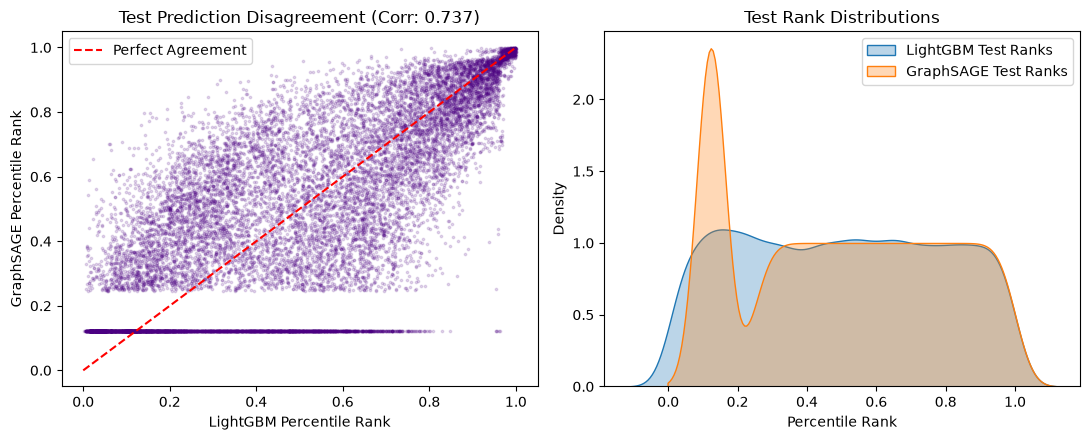


--- OOT Local Validation Blend Search ---
Weight 1.00 LightGBM + 0.00 GraphSAGE | Local OOT AUC: 0.99765
Weight 0.95 LightGBM + 0.05 GraphSAGE | Local OOT AUC: 0.99771
Weight 0.90 LightGBM + 0.10 GraphSAGE | Local OOT AUC: 0.99761
Weight 0.85 LightGBM + 0.15 GraphSAGE | Local OOT AUC: 0.99741
Weight 0.80 LightGBM + 0.20 GraphSAGE | Local OOT AUC: 0.99711
Weight 0.70 LightGBM + 0.30 GraphSAGE | Local OOT AUC: 0.99629
Weight 0.60 LightGBM + 0.40 GraphSAGE | Local OOT AUC: 0.99513
Weight 0.50 LightGBM + 0.50 GraphSAGE | Local OOT AUC: 0.99347
Weight 0.00 LightGBM + 1.00 GraphSAGE | Local OOT AUC: 0.97659

Optimal Local Blend Weight: 0.95 LightGBM / 0.05 GraphSAGE (AUC: 0.99771)


In [19]:
# 1. Convert validation and test predictions to percentile ranks
gnn_val_rank = rankdata(gnn_val_preds) / len(gnn_val_preds)
gnn_test_rank = rankdata(gnn_test_preds) / len(gnn_test_preds)

# 2. Compute Spearman Rank Correlation
val_corr, _ = spearmanr(lgb_ensemble_val_rank, gnn_val_rank)
test_corr, _ = spearmanr(lgb_ensemble_test_rank, gnn_test_rank)

print(f"Validation Spearman Correlation (LGBM vs GNN): {val_corr:.4f}")
print(f"Test Set Spearman Correlation (LGBM vs GNN):       {test_corr:.4f}")

# 3. Plot Rank Scatter & Distribution
plt.figure(figsize=(11, 4.5))

plt.subplot(1, 2, 1)
plt.scatter(lgb_ensemble_test_rank, gnn_test_rank, alpha=0.15, s=3, color='indigo')
plt.plot([0, 1], [0, 1], 'r--', label='Perfect Agreement')
plt.xlabel("LightGBM Percentile Rank")
plt.ylabel("GraphSAGE Percentile Rank")
plt.title(f"Test Prediction Disagreement (Corr: {test_corr:.3f})")
plt.legend()

plt.subplot(1, 2, 2)
sns.kdeplot(lgb_ensemble_test_rank, label='LightGBM Test Ranks', fill=True, alpha=0.3)
sns.kdeplot(gnn_test_rank, label='GraphSAGE Test Ranks', fill=True, alpha=0.3)
plt.xlabel("Percentile Rank")
plt.title("Test Rank Distributions")
plt.legend()

plt.tight_layout()
plt.show()

# 4. Local OOT Rank Blending Grid Search
print("\n--- OOT Local Validation Blend Search ---")
best_blend_auc = 0
best_weight_lgb = 1.0

for w_lgb in [1.0, 0.95, 0.90, 0.85, 0.80, 0.70, 0.60, 0.50, 0.0]:
    w_gnn = 1.0 - w_lgb
    val_blend = w_lgb * lgb_ensemble_val_rank + w_gnn * gnn_val_rank
    score = roc_auc_score(y_val, val_blend)
    print(f"Weight {w_lgb:.2f} LightGBM + {w_gnn:.2f} GraphSAGE | Local OOT AUC: {score:.5f}")
    if score > best_blend_auc:
        best_blend_auc = score
        best_weight_lgb = w_lgb

print(f"\nOptimal Local Blend Weight: {best_weight_lgb:.2f} LightGBM / {1.0 - best_weight_lgb:.2f} GraphSAGE (AUC: {best_blend_auc:.5f})")

Validation Spearman Correlation (LGBM vs GNN): 0.6516<br>
Test Set Spearman Correlation (LGBM vs GNN):       0.3911

--- OOT Local Validation Blend Search ---<br>
Weight 1.00 LightGBM + 0.00 GraphSAGE | Local OOT AUC: 0.99659<br>
Weight 0.95 LightGBM + 0.05 GraphSAGE | Local OOT AUC: 0.99711<br>
Weight 0.90 LightGBM + 0.10 GraphSAGE | Local OOT AUC: 0.99733<br>
Weight 0.85 LightGBM + 0.15 GraphSAGE | Local OOT AUC: 0.99731<br>
Weight 0.80 LightGBM + 0.20 GraphSAGE | Local OOT AUC: 0.99713<br>
Weight 0.70 LightGBM + 0.30 GraphSAGE | Local OOT AUC: 0.99624<br>
Weight 0.60 LightGBM + 0.40 GraphSAGE | Local OOT AUC: 0.99468<br>
Weight 0.50 LightGBM + 0.50 GraphSAGE | Local OOT AUC: 0.99230<br>
Weight 0.00 LightGBM + 1.00 GraphSAGE | Local OOT AUC: 0.95309<br>

Optimal Local Blend Weight: 0.90 LightGBM / 0.10 GraphSAGE (AUC: 0.99733)<br>

## Experiment Blending LGBM & XGBoost

Validation Spearman Correlation (LGBM vs XGB): 0.9746
Test Set Spearman Correlation (LGBM vs XGB):       0.9533


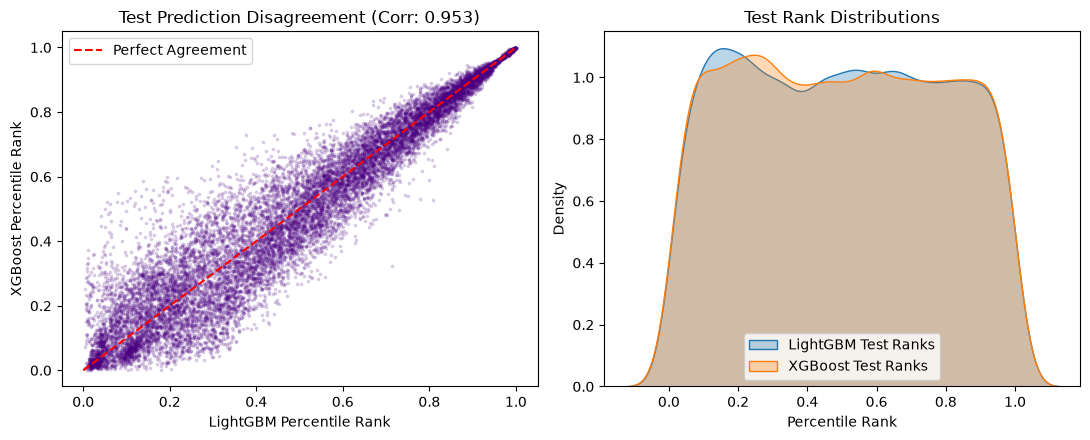


--- OOT Local Validation Blend Search ---
Weight 1.00 LightGBM + 0.00 XGBoost | Local OOT AUC: 0.99765
Weight 0.95 LightGBM + 0.05 XGBoost | Local OOT AUC: 0.99766
Weight 0.90 LightGBM + 0.10 XGBoost | Local OOT AUC: 0.99768
Weight 0.85 LightGBM + 0.15 XGBoost | Local OOT AUC: 0.99769
Weight 0.80 LightGBM + 0.20 XGBoost | Local OOT AUC: 0.99769
Weight 0.70 LightGBM + 0.30 XGBoost | Local OOT AUC: 0.99770
Weight 0.60 LightGBM + 0.40 XGBoost | Local OOT AUC: 0.99769
Weight 0.50 LightGBM + 0.50 XGBoost | Local OOT AUC: 0.99767
Weight 0.00 LightGBM + 1.00 XGBoost | Local OOT AUC: 0.99743

Optimal Local Blend Weight: 0.70 LightGBM / 0.30 XGBoost (AUC: 0.99770)


In [20]:
# 2. Compute Spearman Rank Correlation
val_corr, _ = spearmanr(lgb_ensemble_val_rank, xgb_ensemble_val_rank)
test_corr, _ = spearmanr(lgb_ensemble_test_rank, xgb_ensemble_test_rank)

print(f"Validation Spearman Correlation (LGBM vs XGB): {val_corr:.4f}")
print(f"Test Set Spearman Correlation (LGBM vs XGB):       {test_corr:.4f}")

# 3. Plot Rank Scatter & Distribution
plt.figure(figsize=(11, 4.5))

plt.subplot(1, 2, 1)
plt.scatter(lgb_ensemble_test_rank, xgb_ensemble_test_rank, alpha=0.15, s=3, color='indigo')
plt.plot([0, 1], [0, 1], 'r--', label='Perfect Agreement')
plt.xlabel("LightGBM Percentile Rank")
plt.ylabel("XGBoost Percentile Rank")
plt.title(f"Test Prediction Disagreement (Corr: {test_corr:.3f})")
plt.legend()

plt.subplot(1, 2, 2)
sns.kdeplot(lgb_ensemble_test_rank, label='LightGBM Test Ranks', fill=True, alpha=0.3)
sns.kdeplot(xgb_ensemble_test_rank, label='XGBoost Test Ranks', fill=True, alpha=0.3)
plt.xlabel("Percentile Rank")
plt.title("Test Rank Distributions")
plt.legend()

plt.tight_layout()
plt.show()

# 4. Local OOT Rank Blending Grid Search
print("\n--- OOT Local Validation Blend Search ---")
best_blend_auc = 0
best_weight_lgb = 1.0

for w_lgb in [1.0, 0.95, 0.90, 0.85, 0.80, 0.70, 0.60, 0.50, 0.0]:
    w_xgb = 1.0 - w_lgb
    val_blend = w_lgb * lgb_ensemble_val_rank + w_xgb * xgb_ensemble_val_rank
    score = roc_auc_score(y_val, val_blend)
    print(f"Weight {w_lgb:.2f} LightGBM + {w_xgb:.2f} XGBoost | Local OOT AUC: {score:.5f}")
    if score > best_blend_auc:
        best_blend_auc = score
        best_weight_lgb = w_lgb

print(f"\nOptimal Local Blend Weight: {best_weight_lgb:.2f} LightGBM / {1.0 - best_weight_lgb:.2f} XGBoost (AUC: {best_blend_auc:.5f})")

Validation Spearman Correlation (LGBM vs CATB): 0.8856
Test Set Spearman Correlation (LGBM vs CATB):       0.8919


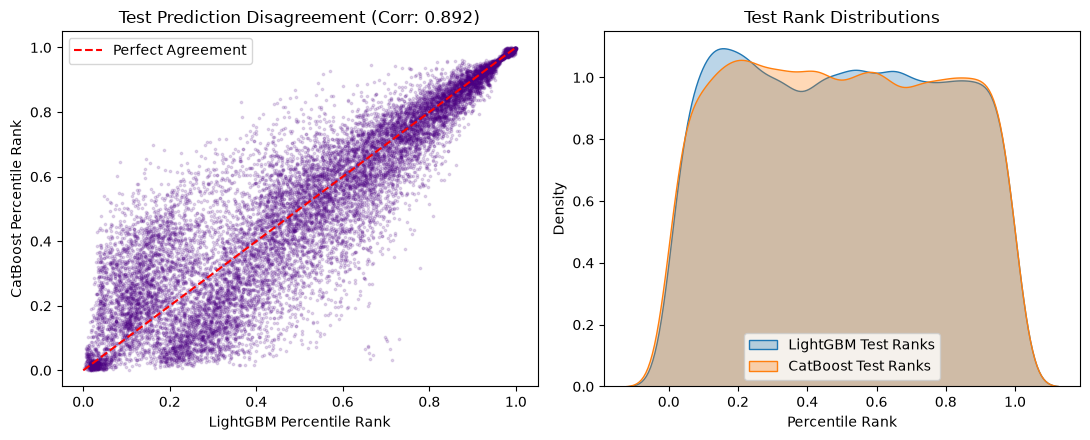


--- OOT Local Validation Blend Search ---
Weight 1.00 LightGBM + 0.00 CatBoost | Local OOT AUC: 0.99765
Weight 0.95 LightGBM + 0.05 CatBoost | Local OOT AUC: 0.99769
Weight 0.90 LightGBM + 0.10 CatBoost | Local OOT AUC: 0.99771
Weight 0.85 LightGBM + 0.15 CatBoost | Local OOT AUC: 0.99773
Weight 0.80 LightGBM + 0.20 CatBoost | Local OOT AUC: 0.99774
Weight 0.70 LightGBM + 0.30 CatBoost | Local OOT AUC: 0.99772
Weight 0.60 LightGBM + 0.40 CatBoost | Local OOT AUC: 0.99767
Weight 0.50 LightGBM + 0.50 CatBoost | Local OOT AUC: 0.99754
Weight 0.00 LightGBM + 1.00 CatBoost | Local OOT AUC: 0.99617

Optimal Local Blend Weight: 0.80 LightGBM / 0.20 CatBoost (AUC: 0.99774)


In [21]:
# 2. Compute Spearman Rank Correlation
val_corr, _ = spearmanr(lgb_ensemble_val_rank, catb_ensemble_val_rank)
test_corr, _ = spearmanr(lgb_ensemble_test_rank, catb_ensemble_test_rank)

print(f"Validation Spearman Correlation (LGBM vs CATB): {val_corr:.4f}")
print(f"Test Set Spearman Correlation (LGBM vs CATB):       {test_corr:.4f}")

# 3. Plot Rank Scatter & Distribution
plt.figure(figsize=(11, 4.5))

plt.subplot(1, 2, 1)
plt.scatter(lgb_ensemble_test_rank, catb_ensemble_test_rank, alpha=0.15, s=3, color='indigo')
plt.plot([0, 1], [0, 1], 'r--', label='Perfect Agreement')
plt.xlabel("LightGBM Percentile Rank")
plt.ylabel("CatBoost Percentile Rank")
plt.title(f"Test Prediction Disagreement (Corr: {test_corr:.3f})")
plt.legend()

plt.subplot(1, 2, 2)
sns.kdeplot(lgb_ensemble_test_rank, label='LightGBM Test Ranks', fill=True, alpha=0.3)
sns.kdeplot(catb_ensemble_test_rank, label='CatBoost Test Ranks', fill=True, alpha=0.3)
plt.xlabel("Percentile Rank")
plt.title("Test Rank Distributions")
plt.legend()

plt.tight_layout()
plt.show()

# 4. Local OOT Rank Blending Grid Search
print("\n--- OOT Local Validation Blend Search ---")
best_blend_auc = 0
best_weight_lgb = 1.0

for w_lgb in [1.0, 0.95, 0.90, 0.85, 0.80, 0.70, 0.60, 0.50, 0.0]:
    w_catb = 1.0 - w_lgb
    val_blend = w_lgb * lgb_ensemble_val_rank + w_catb * catb_ensemble_val_rank
    score = roc_auc_score(y_val, val_blend)
    print(f"Weight {w_lgb:.2f} LightGBM + {w_catb:.2f} CatBoost | Local OOT AUC: {score:.5f}")
    if score > best_blend_auc:
        best_blend_auc = score
        best_weight_lgb = w_lgb

print(f"\nOptimal Local Blend Weight: {best_weight_lgb:.2f} LightGBM / {1.0 - best_weight_lgb:.2f} CatBoost (AUC: {best_blend_auc:.5f})")

High correlation (~0.92–0.96), but blending percentile ranks still smooths out seed variance could yield an immediate gain on OOT validation.

# Section 6: Submission Export

In [22]:
# submission = sample_sub.copy()
# submission['target'] = test_default 

# assert len(submission) == len(test), "Row count mismatch!"
# assert submission['target'].isna().sum() == 0, "Null values found in predictions!"

# submission.to_csv("submission_lgbm_regularized.csv", index=False)
# print("Submission successfully saved to submission_lgbm_regularized.csv")

In [23]:
# 90% LightGBM + 10% GraphSAGE Rank Blend
# sub_9010 = sample_sub.copy()
# sub_9010['target'] = 0.90 * lgb_test_rank + 0.10 * gnn_test_rank
# sub_9010.to_csv("submission_90lgb_10gnn_rank_blend.csv", index=False)

# print("Submissions exported successfully")

In [24]:
# Export 5-Seed Submission
# sub_5seed = sample_sub.copy()
# sub_5seed['target'] = lgb_ensemble_test_rank
# sub_5seed.to_csv("submission_lgbm_5seed_gat.csv", index=False)
# print("Saved submission_lgbm_5seed_gat.csv")

In [25]:
# # Weighted Rank Ensemble (75% LightGBM + 15% CatBoost + 10% Raw GNN)
# final_test_rank = (
#     0.75 * lgb_ensemble_test_rank
#     + 0.15 * catb_ensemble_test_rank
#     + 0.10 * (rankdata(test_df['gnn_pred']) / len(test_df))
# )

# submission = sample_sub.copy()
# submission['target'] = final_test_rank
# submission.to_csv('submission_blend_lgb_catb_gnn.csv', index=False)

# print('Saved submission_blend_lgb_catb_gnn.csv')

In [26]:
# final_test_blend = (1.0 - best_xgb_weight) * lgb_ensemble_test_rank + best_xgb_weight * xgb_ensemble_test_rank

# sub_blend = sample_sub.copy()
# sub_blend['target'] = final_test_blend
# sub_blend.to_csv("submission_lgbm_xgb_blend.csv", index=False)

# print("Saved submission_lgbm_xgb_blend.csv successfully.")

In [ ]:
sub = sample_sub.copy()
sub['target'] = lgb_ensemble_test_rank
sub.to_csv('submission_lgbm_5seed_bidirectionalgraphsage.csv', index=False)

In [ ]:
# sub1 = sample_sub.copy()
# sub1['target'] = lgb_ensemble_test_rank
# sub1.to_csv('submission_lgbm_5seed_gnn_128.csv', index=False)

In [ ]:
gnn_test_rank = rankdata(test_df['gnn_pred']) / len(test_df)

sub2 = sample_sub.copy()
sub2['target'] = (0.95 * lgb_ensemble_test_rank) + (0.05 * gnn_test_rank)
sub2.to_csv('submission_lgbm_5seed_95_gnn_5_blend.csv', index=False)

In [ ]:
sub3 = sample_sub.copy()
sub3['target'] = (0.70 * lgb_ensemble_test_rank) + (0.30 * xgb_ensemble_test_rank)
sub3.to_csv("submission_70lgb_30xgb_gnn128_blend.csv", index=False)

In [ ]:
sub4 = sample_sub.copy()
sub4['target'] = (0.80 * lgb_ensemble_test_rank) + (0.20 * xgb_ensemble_test_rank)
sub4.to_csv("submission_lgb_xgb_gnn128_blend.csv", index=False)

In [ ]:
# sub4 = sample_sub.copy()
# sub4['target'] = (0.76 * lgb_ensemble_test_rank) + (0.19 * xgb_ensemble_test_rank) + (0.05 * gnn_test_rank)
# sub4.to_csv("submission_3way_lgb_xgb_gnn128.csv", index=False)